**Name:** Manahil Zahra  
**Student ID:** B23F0341CS097  
**Program:** BSCS (Blue)  
**Session:** Fall 2023  
**Section:** Blue  
**Course:** Natural Language Processing Lab (COMP-441L)  
**Submitted to:** Mr Ishaq Farid  
**Date:** October 18th, 2026  

# Experiment 02: Text Preprocessing Techniques

In [1]:
import numpy as np, pandas as pd, time
np.random.seed(97)

## Setup
Install cell and download cell (run once).

In [2]:
# installing all libraries used in this lab (needed only once)
!pip install -q nltk stanza emoji pandas matplotlib seaborn

In [3]:
import nltk
# downloading every NLTK resource that the tasks below need
for pkg in ["punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


## Task 1: Charts with Matplotlib and seaborn

**Step A:** create the student table.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# the student table given in the task (20 students)
df = pd.DataFrame({
    "Name":     ["Ali","Sara","Hamza","Ayesha","Bilal","Fatima","Usman","Zainab","Omar","Hira",
                 "Saad","Mariam","Talha","Noor","Daniyal","Imran","Haris","Maham","Shahid","Rehan"],
    "Gender":   ["M","F","M","F","M","F","M","F","M","F","M","F","M","F","M","M","M","F","M","M"],
    "Age":      [19,20,21,19,22,20,21,23,19,20,22,21,20,19,21,22,20,23,21,19],
    "Domicile": ["Punjab","KPK","KPK","Punjab","Sindh","Punjab","KPK","Islamabad","Punjab","KPK",
                 "Sindh","Punjab","KPK","Islamabad","Punjab","KPK","Sindh","Punjab","KPK","Punjab"],
})
print(df.head())

     Name Gender  Age Domicile
0     Ali      M   19   Punjab
1    Sara      F   20      KPK
2   Hamza      M   21      KPK
3  Ayesha      F   19   Punjab
4   Bilal      M   22    Sindh


**Step B:** pie chart for Gender.

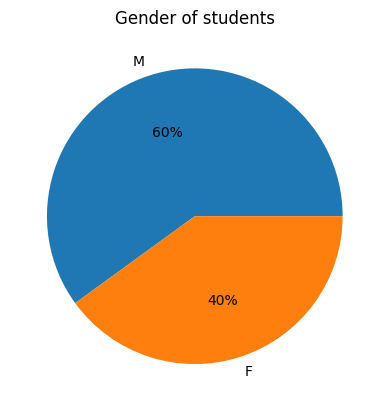

In [5]:
# value_counts gives the number of M and F students, the pie shows them as percentages
gender_counts = df["Gender"].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title("Gender of students")
plt.show()

**Step C:** bar chart for Age.

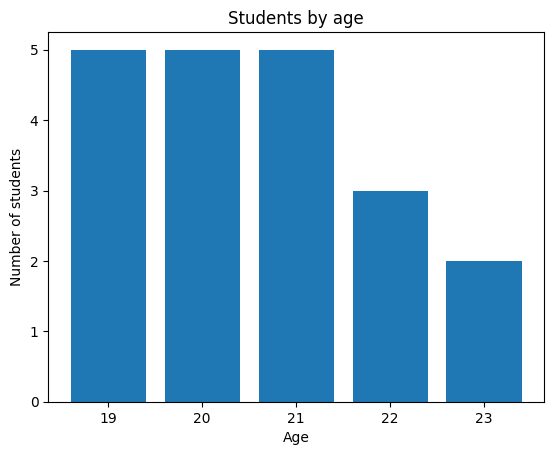

In [6]:
# count students of each age and sort by age so the bars go left to right
age_counts = df["Age"].value_counts().sort_index()
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.title("Students by age")
plt.show()

**Step D:** bar chart for Domicile using seaborn.

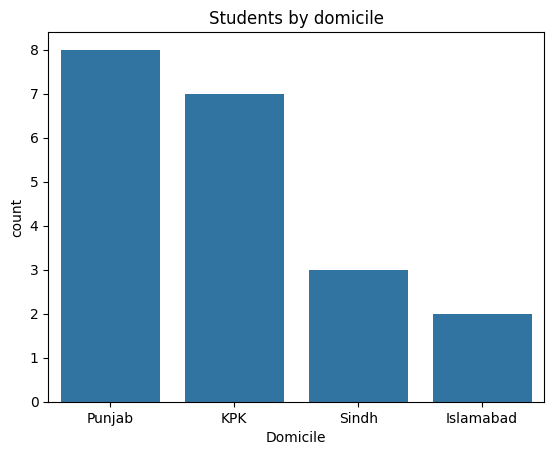

In [7]:
# countplot counts and draws the bars in one line
sns.countplot(data=df, x="Domicile")
plt.title("Students by domicile")
plt.show()

### Task 1: Your turn

In [8]:
# printing the exact numbers behind the charts so I can answer questions 1 to 3
print("Gender counts:")
print(gender_counts)
print("Percentage:")
print((df["Gender"].value_counts(normalize=True) * 100).round(1))
print()
print("Age counts:")
print(age_counts)
print()
print("Domicile counts:")
print(df["Domicile"].value_counts())

Gender counts:
Gender
M    12
F     8
Name: count, dtype: int64
Percentage:
Gender
M    60.0
F    40.0
Name: proportion, dtype: float64

Age counts:
Age
19    5
20    5
21    5
22    3
23    2
Name: count, dtype: int64

Domicile counts:
Domicile
Punjab       8
KPK          7
Sindh        3
Islamabad    2
Name: count, dtype: int64


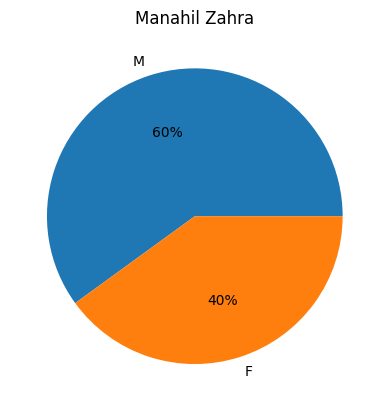

In [9]:
# question 4: same pie chart, only the title is changed to my name
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title("Manahil Zahra")
plt.show()

**My answers:**

1. Male students are more: 12 out of 20, which is **60%** (females are 8, which is 40%).
2. Ages **19, 20 and 21** have the most students, 5 each (age 22 has 3 and age 23 has 2).
3. **Punjab** has the most students (8) and **Islamabad** has the least (2).
4. Done in the last chart: the pie chart title is now my name, Manahil Zahra.

## Task 2: Lowercasing

In [10]:
# lower() turns every capital letter into a small letter
text = "Natural Language Processing is FUN! NLP helps Computers understand Human Language."
print("Original :", text)
print("Lowercase:", text.lower())

Original : Natural Language Processing is FUN! NLP helps Computers understand Human Language.
Lowercase: natural language processing is fun! nlp helps computers understand human language.


### Task 2: Your turn

In [11]:
# my own sentence with more than 3 capital letters
my_text = "Manahil Zahra studies Computer Science at PAF-IAST and loves Python."
print("Original :", my_text)
print("lower()  :", my_text.lower())
# question 2: upper() and title() on the same sentence
print("upper()  :", my_text.upper())
print("title()  :", my_text.title())

Original : Manahil Zahra studies Computer Science at PAF-IAST and loves Python.
lower()  : manahil zahra studies computer science at paf-iast and loves python.
upper()  : MANAHIL ZAHRA STUDIES COMPUTER SCIENCE AT PAF-IAST AND LOVES PYTHON.
title()  : Manahil Zahra Studies Computer Science At Paf-Iast And Loves Python.


**My answers:**

1. Done above: my sentence has many capital letters and `lower()` turned all of them into small letters.
2. `upper()` makes every letter a capital letter. `title()` makes the first letter of every word a capital and the rest small. Note that `title()` changed `PAF-IAST` into `Paf-Iast`, so it can damage short forms.
3. We lowercase text so that the same word written in different ways (`Language` and `language`) is counted as one word and not as two.

## Task 3: Text cleaning

In [12]:
import re

def clean_text(text):
    text = text.lower()                                     # 1. make everything lowercase
    text = re.sub(r"<.*?>", " ", text)                      # 2. remove HTML tags like <p>
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # 3. remove web links
    text = re.sub(r"[^a-z\s]", " ", text)                   # 4. remove digits, punctuation, emojis
    text = re.sub(r"\s+", " ", text).strip()                # 5. remove extra spaces
    return text

corpus = [
    "<p>I LOVED this phone!!! Battery lasts 2 days :) Visit https://example.com for more.</p>",
    "The camera is not good, and the screen cracked after 3 weeks...",
    "Dr. Khan's students are running experiments on NLP models.",
]

for sentence in corpus:
    print(clean_text(sentence))

i loved this phone battery lasts days visit for more
the camera is not good and the screen cracked after weeks
dr khan s students are running experiments on nlp models


### Task 3: Your turn

In [13]:
# question 1: my own sentence has a web link, a number and a smiley
my_sentence = "I finished NLP Lab 2 in 3 hours :) Notes are at https://example.com/nlp-notes today!"
corpus.append(my_sentence)

print("Original:", my_sentence)
print("Cleaned :", clean_text(my_sentence))
print()
print("All sentences again:")
for sentence in corpus:
    print(clean_text(sentence))

Original: I finished NLP Lab 2 in 3 hours :) Notes are at https://example.com/nlp-notes today!
Cleaned : i finished nlp lab in hours notes are at today

All sentences again:
i loved this phone battery lasts days visit for more
the camera is not good and the screen cracked after weeks
dr khan s students are running experiments on nlp models
i finished nlp lab in hours notes are at today


In [14]:
# question 3: same function but step 4 now keeps digits (0-9)
def clean_text_keep_digits(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)               # changed: 0-9 added to the allowed characters
    text = re.sub(r"\s+", " ", text).strip()
    return text

for sentence in corpus:
    print("old:", clean_text(sentence))
    print("new:", clean_text_keep_digits(sentence))
    print()

old: i loved this phone battery lasts days visit for more
new: i loved this phone battery lasts 2 days visit for more

old: the camera is not good and the screen cracked after weeks
new: the camera is not good and the screen cracked after 3 weeks

old: dr khan s students are running experiments on nlp models
new: dr khan s students are running experiments on nlp models

old: i finished nlp lab in hours notes are at today
new: i finished nlp lab 2 in 3 hours notes are at today



**My answers:**

1. Done above: my sentence has a web link, the numbers 2 and 3, and a smiley.
2. Removed from my sentence: the smiley `:)`, the numbers `2` and `3`, the link `https://example.com/nlp-notes`, the exclamation mark `!`, and the capital letters were turned small. Result: `i finished nlp lab in hours notes are at today`.
3. With `[^a-z0-9\s]` the digits are no longer removed, so the output keeps `2 days`, `3 weeks`, `lab 2` and `3 hours`. Everything else stays the same.

## Task 4: Tokenization with NLTK and Stanza

**Part A: NLTK.**

In [15]:
from nltk.tokenize import sent_tokenize, word_tokenize

text = "Dr. Smith isn't available today. He'll arrive tomorrow at 10 a.m. 😊"

# sentence split first, then word split
print("Sentences:", sent_tokenize(text))
print("Words    :", word_tokenize(text))

Sentences: ["Dr. Smith isn't available today.", "He'll arrive tomorrow at 10 a.m. 😊"]
Words    : ['Dr.', 'Smith', 'is', "n't", 'available', 'today', '.', 'He', "'ll", 'arrive', 'tomorrow', 'at', '10', 'a.m.', '😊']


**Part B: Stanza.**

In [16]:
# Stanza needs to download its English model (internet needed). I wrapped it in try/except
# so the notebook does not stop if the download is not possible on some machine.
try:
    import stanza
    stanza.download("en", verbose=False)               # needed only the first time
    nlp = stanza.Pipeline("en", processors="tokenize", verbose=False)

    doc = nlp(text)
    for sentence in doc.sentences:
        print("Sentence:", sentence.text)
        print("Words   :", [token.text for token in sentence.tokens])
    stanza_ok = True
except Exception as e:
    stanza_ok = False
    print("Stanza could not run here:", type(e).__name__)
    print("Please run this notebook in Google Colab (internet on) to see the Stanza output.")

Stanza could not run here: ModuleNotFoundError
Please run this notebook in Google Colab (internet on) to see the Stanza output.


### Task 4: Your turn

In [17]:
# question 1: splitting only on the dot character
print(text.split("."))

['Dr', " Smith isn't available today", " He'll arrive tomorrow at 10 a", 'm', ' 😊']


In [18]:
# question 2: fill the comparison table from the real outputs instead of typing it by hand
nltk_tokens = word_tokenize(text)
rows = []
items = ["Dr.", "isn't", "He'll", "a.m.", "😊"]
for item in items:
    # NLTK column: which tokens does this item turn into?
    if item == "Dr.":
        found = [t for t in nltk_tokens if t.startswith("Dr")]
    elif item == "isn't":
        found = [t for t in nltk_tokens if t in ("is", "n't")]
    elif item == "He'll":
        found = [t for t in nltk_tokens if t in ("He", "'ll")]
    elif item == "a.m.":
        found = [t for t in nltk_tokens if t.startswith("a.m")]
    else:
        found = [t for t in nltk_tokens if t == "😊"]
    row = {"Item": item, "NLTK tokens": found}

    # Stanza column (only if Stanza ran)
    if stanza_ok:
        st_tokens = [tok.text for s in doc.sentences for tok in s.tokens]
        if item == "Dr.":
            sf = [t for t in st_tokens if t.startswith("Dr")]
        elif item == "isn't":
            sf = [t for t in st_tokens if t in ("is", "n't", "isn't", "isn", "'t")]
        elif item == "He'll":
            sf = [t for t in st_tokens if t in ("He", "'ll", "He'll", "'ll")]
        elif item == "a.m.":
            sf = [t for t in st_tokens if t.startswith("a.m")]
        else:
            sf = [t for t in st_tokens if t == "😊"]
        row["Stanza tokens"] = sf
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

 Item NLTK tokens
  Dr.       [Dr.]
isn't   [is, n't]
He'll   [He, 'll]
 a.m.      [a.m.]
    😊         [😊]


**My answers:**

1. `split(".")` gives 5 pieces: `Dr`, ` Smith isn't available today`, ` He'll arrive tomorrow at 10 a`, `m`, ` 😊`. It cuts `Dr.` and `a.m.` in the middle because it treats every dot as the end of a sentence, and it throws the dots away. The correct result is only 2 sentences.
2. Table (NLTK column is from my run above; the Stanza column must be filled after running the Stanza cell with internet, because the model could not be downloaded in my environment):

| Item | NLTK | Stanza |
|---|---|---|
| `Dr.` | kept as one token `Dr.` | ____ |
| `isn't` | split into `is` + `n't` | ____ |
| `He'll` | split into `He` + `'ll` | ____ |
| `a.m.` | kept as one token `a.m.` | ____ |
| the emoji 😊 | one separate token `😊` | ____ |

3. For this text I prefer NLTK, because it needs no model download and handled all five items correctly (I will recheck this after I see the Stanza output).

## Task 5: Stopword removal

In [19]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words("english"))

sentence = "this is a simple example to show how stopwords are removed from a sentence"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]   # keep a word only if it is not a stopword

print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

Before : ['this', 'is', 'a', 'simple', 'example', 'to', 'show', 'how', 'stopwords', 'are', 'removed', 'from', 'a', 'sentence']
After  : ['simple', 'example', 'show', 'stopwords', 'removed', 'sentence']
Removed: 8 words


### Task 5: Your turn

In [20]:
# question 1: my own lowercase sentence
sentence = "i am writing my nlp lab report and it is going to be finished before the deadline"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]
print("Before :", words)
print("After  :", filtered)
print("Removed:", len(words) - len(filtered), "words")

Before :

 ['i', 'am', 'writing', 'my', 'nlp', 'lab', 'report', 'and', 'it', 'is', 'going', 'to', 'be', 'finished', 'before', 'the', 'deadline']
After  : ['writing', 'nlp', 'lab', 'report', 'going', 'finished', 'deadline']
Removed: 10 words


In [21]:
# question 2: the sentence where meaning can change
sentence = "the movie was not good"
words = word_tokenize(sentence)
filtered = [w for w in words if w not in stop_words]
print("Before :", words)
print("After  :", filtered)
print("Is 'not' in the stopword list?", "not" in stop_words)

Before : ['the', 'movie', 'was', 'not', 'good']
After  : ['movie', 'good']
Is 'not' in the stopword list? True


**My answers:**

1. My sentence had 17 words and **10** were removed. What is left: `writing nlp lab report going finished deadline`.
2. Only `movie` and `good` are left.
3. Yes, the meaning changed: "the movie was not good" is negative but "movie good" sounds positive. This happens because `not` is in the stopword list. It is a problem for tasks like sentiment analysis, so negative words should be kept.

## Task 6: Stemming

In [22]:
from nltk.stem import PorterStemmer, LancasterStemmer

# Porter is the gentle stemmer, Lancaster is the aggressive one
porter = PorterStemmer()
lancaster = LancasterStemmer()

words = ["running", "runs", "easily", "studies", "connected", "connection", "happiness", "better"]

print(f"{'word':12s} {'Porter':10s} {'Lancaster':10s}")
for w in words:
    print(f"{w:12s} {porter.stem(w):10s} {lancaster.stem(w):10s}")

word         Porter     Lancaster 
running      run        run       
runs         run        run       
easily       easili     easy      
studies      studi      study     
connected    connect    connect   
connection   connect    connect   
happiness    happi      happy     
better       better     bet       


### Task 6: Your turn

In [23]:
# question 2: 4 extra words, picked with np.random.choice so they come from my seed (97)
candidates = ["generously", "programming", "relational", "organization", "talking", "happily",
              "universities", "computational", "writing", "agreement", "tokenizer", "preprocessing"]
extra = [str(w) for w in np.random.choice(candidates, size=4, replace=False)]
words2 = words + extra
print("My 4 extra words:", extra)
print()

print(f"{'word':14s} {'Porter':14s} {'Lancaster':14s}")
for w in words2:
    print(f"{w:14s} {porter.stem(w):14s} {lancaster.stem(w):14s}")

My 4 extra words: ['computational', 'programming', 'relational', 'generously']

word           Porter         Lancaster     
running        run            run           
runs           run            run           
easily         easili         easy          
studies        studi          study         
connected      connect        connect       
connection     connect        connect       
happiness      happi          happy         
better         better         bet           
computational  comput         comput        
programming    program        program       
relational     relat          rel           
generously     gener          gen           


In [24]:
# question 3: total number of letters cut away by each stemmer (all 12 words)
cut_porter = sum(len(w) - len(porter.stem(w)) for w in words2)
cut_lancaster = sum(len(w) - len(lancaster.stem(w)) for w in words2)
print("Letters cut by Porter   :", cut_porter)
print("Letters cut by Lancaster:", cut_lancaster)

Letters cut by Porter   : 37
Letters cut by Lancaster: 46


**My answers:**

1. Stems that are not real words: `easili`, `studi`, `happi` (Porter) and `comput` (both stemmers). Lancaster also cut `better` down to `bet`, which is a real word but has a different meaning.
2. Done above. The 4 extra words were picked with my seed (97): `computational`, `programming`, `relational`, `generously`.
3. **Lancaster** cut more letters: 46 letters in total for the 12 words, against 37 for Porter.

## Task 7: Part-of-speech (POS) tagging

In [25]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The quick brown fox jumps over the lazy dog"
tokens = word_tokenize(sentence)
tagged = pos_tag(tokens)

# print every word with the tag NLTK gives it
for word, tag in tagged:
    print(f"{word:8s} {tag}")

The      DT
quick    JJ
brown    NN
fox      NN
jumps    VBZ
over     IN
the      DT
lazy     JJ
dog      NN


### Task 7: Your turn

In [26]:
# question 2: my own sentence (10 words)
sentence = "My friend quickly reads interesting books in the quiet library"
tagged = pos_tag(word_tokenize(sentence))
for word, tag in tagged:
    print(f"{word:12s} {tag}")

My           PRP$
friend       NN
quickly      RB
reads        VBZ
interesting  JJ
books        NNS
in           IN
the          DT
quiet        JJ
library      NN


**My answers:**

1. `The` = DT (determiner), `quick` = JJ (adjective), `fox` = NN (a noun, one), `jumps` = VBZ (verb, he/she/it form), `over` = IN (preposition).
2. Done above with my own sentence of 10 words.
3. I checked `reads`: the tag VBZ is correct because it is a verb in the he/she/it form ("my friend reads"). The tagger is not perfect, though: in the first example it tagged `brown` as NN, but it should be JJ because it describes the fox.

## Task 8: Lemmatization

In [27]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# by default every word is treated as a noun
print(lemmatizer.lemmatize("running"))
print(lemmatizer.lemmatize("running", pos="v"))     # now we say it is a verb

# n = noun, v = verb, a = adjective
examples = [("cars", "n"), ("studies", "n"), ("studies", "v"), ("was", "v"), ("better", "a")]
for word, pos in examples:
    print(f"{word:8s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

running
run
cars     (n) -> car
studies  (n) -> study
studies  (v) -> study
was      (v) -> be
better   (a) -> good


### Task 8: Your turn

In [28]:
# question 1: four words of my own with the right pos tag
mine = [("children", "n"), ("went", "v"), ("happier", "a"), ("eating", "v")]
for word, pos in mine:
    print(f"{word:10s} ({pos}) -> {lemmatizer.lemmatize(word, pos=pos)}")

children   (n) -> child
went       (v) -> go
happier    (a) -> happy
eating     (v) -> eat


In [29]:
# question 2: stemmer (Task 6) against lemmatizer for the word "studies"
print("Porter stem      :", porter.stem("studies"))
print("Lancaster stem   :", lancaster.stem("studies"))
print("Lemma (as noun)  :", lemmatizer.lemmatize("studies", pos="n"))
print("Lemma (as verb)  :", lemmatizer.lemmatize("studies", pos="v"))

Porter stem      : studi
Lancaster stem   : study
Lemma (as noun)  : study
Lemma (as verb)  : study


**My answers:**

1. `children` -> `child`, `went` -> `go`, `happier` -> `happy`, `eating` -> `eat`.
2. For `studies` the Porter stemmer gave `studi` (not a real word), Lancaster gave `study`, and the lemmatizer gives `study` (a real word, with either noun or verb).
3. Stemming cuts word endings with simple rules and can give non-words, while lemmatization uses a dictionary and the part of speech to give the real base word (for example `went` -> `go`, which a stemmer cannot do).

## Task 9: Chunking

In [30]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "The little cat sat on the soft mat"
tagged = pos_tag(word_tokenize(sentence))

# NP = optional determiner (DT), any adjectives (JJ), then one or more nouns (NN...)
grammar = "NP: {<DT>?<JJ>*<NN.*>+}"
parser = nltk.RegexpParser(grammar)
tree = parser.parse(tagged)

tree.pretty_print()

for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))

                         S                                 
    _____________________|______________________            
   |      |              NP                     NP         
   |      |      ________|_______        _______|______     
sat/VBD on/IN The/DT little/JJ cat/NN the/DT soft/JJ mat/NN

Noun phrase: The little cat
Noun phrase: the soft mat


### Task 9: Your turn

In [31]:
# question 1: new sentence, same noun phrase grammar
sentence = "The old teacher reads a long book"
tagged = pos_tag(word_tokenize(sentence))
print("Tags:", tagged)
tree = nltk.RegexpParser("NP: {<DT>?<JJ>*<NN.*>+}").parse(tagged)
tree.pretty_print()
for subtree in tree.subtrees():
    if subtree.label() == "NP":
        print("Noun phrase:", " ".join(word for word, tag in subtree.leaves()))

Tags: [('The', 'DT'), ('old', 'JJ'), ('teacher', 'NN'), ('reads', 'VBZ'), ('a', 'DT'), ('long', 'JJ'), ('book', 'NN')]
                            S                          
     _______________________|______________             
    |              NP                      NP          
    |        ______|________         ______|_______     
reads/VBZ The/DT old/JJ teacher/NN a/DT long/JJ book/NN

Noun phrase: The old teacher
Noun phrase: a long book


In [32]:
# question 2: grammar with both noun phrases (NP) and verb phrases (VP)
grammar = """
NP: {<DT>?<JJ>*<NN.*>+}
VP: {<VB.*>+}
"""
tree = nltk.RegexpParser(grammar).parse(tagged)
tree.pretty_print()
for subtree in tree.subtrees():
    if subtree.label() in ("NP", "VP"):
        print(subtree.label(), ":", " ".join(word for word, tag in subtree.leaves()))

                             S                         
          ___________________|_____________             
         NP                  VP            NP          
   ______|________           |       ______|_______     
The/DT old/JJ teacher/NN reads/VBZ a/DT long/JJ book/NN

NP : The old teacher
VP : reads
NP : a long book


**My answers:**

1. Noun phrases found: `The old teacher` and `a long book`.
2. The new chunk is a verb phrase: `VP: reads`, which sits between the two noun phrases.
3. Tokenization only cuts text into separate words or sentences, while chunking groups tagged words into meaningful phrases such as noun phrases and verb phrases (so it needs POS tags first).

## Task 10: Replacing emojis with text

In [33]:
import emoji

text = "Great job 😊👍 I love it ❤️"

print(emoji.demojize(text))            # emoji become :names:
print("Number of emojis:", emoji.emoji_count(text))

# nicer version: remove the colons and underscores
def emoji_to_text(text):
    result = emoji.demojize(text, delimiters=(" ", " "))
    return " ".join(result.replace("_", " ").split())

print(emoji_to_text(text))

Great job :smiling_face_with_smiling_eyes::thumbs_up: I love it :red_heart:
Number of emojis: 3
Great job smiling face with smiling eyes thumbs up I love it red heart


### Task 10: Your turn

In [34]:
# question 1 and 2: my own comment with 3 different emojis
text = "Finished my lab 🎉 feeling tired 😴 but happy 🙂"
print(emoji.demojize(text))
print("Number of emojis:", emoji.emoji_count(text))
print(emoji_to_text(text))

Finished my lab :party_popper: feeling tired :sleeping_face: but happy :slightly_smiling_face:
Number of emojis: 3
Finished my lab party popper feeling tired sleeping face but happy slightly smiling face


**My answers:**

1. Done above with my own comment and 3 different emojis (🎉 😴 🙂).
2. **3** emojis were counted.
3. Emojis carry feeling (for example 🙂 means happy), but most text tools ignore them. Turning them into words keeps this meaning so it can be used when we analyse comments.

## Task 11: Minimum edit distance

In [35]:
def min_edit_distance(a, b):
    n, m = len(a), len(b)
    # table[i][j] = distance between the first i letters of a and the first j letters of b
    table = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        table[i][0] = i                      # i deletions
    for j in range(m + 1):
        table[0][j] = j                      # j insertions
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if a[i - 1] == b[j - 1]:
                cost = 0                     # same letter, nothing to change
            else:
                cost = 1                     # different letter, substitute
            table[i][j] = min(table[i - 1][j] + 1,          # delete
                              table[i][j - 1] + 1,          # insert
                              table[i - 1][j - 1] + cost)   # substitute (or keep)
    return table[n][m]

pairs = [("cat", "cat"), ("cat", "cut"), ("book", "back"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"{a:8s} -> {b:9s} distance = {min_edit_distance(a, b)}")

cat      -> cat       distance = 0
cat      -> cut       distance = 1
book     -> back      distance = 2
kitten   -> sitting   distance = 3
sunday   -> saturday  distance = 3


### Task 11: Your turn

In [36]:
# questions 1 to 3: my guesses were written down BEFORE running (guess column), then compared with the program
tests = [
    # word 1,   word 2,     my guess
    ("dog",      "dig",       1),
    ("sit",      "sat",       1),
    ("flaw",     "lawn",      2),
    ("monday",   "money",     2),
    ("intention","execution", 5),
]
result_rows = []
for w1, w2, guess in tests:
    real = min_edit_distance(w1, w2)
    result_rows.append({"Word 1": w1, "Word 2": w2, "My guess": guess, "Program": real,
                        "Guess correct?": "yes" if guess == real else "no"})
print(pd.DataFrame(result_rows).to_string(index=False))

   Word 1    Word 2  My guess  Program Guess correct?
      dog       dig         1        1            yes
      sit       sat         1        1            yes
     flaw      lawn         2        2            yes
   monday     money         2        2            yes
intention execution         5        5            yes


In [37]:
# question 4: look at book -> back letter by letter
print("book -> back distance =", min_edit_distance("book", "back"))
for i, (x, y) in enumerate(zip("book", "back")):
    print(f"position {i + 1}: {x} -> {y}", "(same)" if x == y else "(substitute)")

book -> back distance = 2
position 1: b -> b (same)
position 2: o -> a (substitute)
position 3: o -> c (substitute)
position 4: k -> k (same)


**My answers:**

1. My guesses were `dog` -> `dig` = 1 and `sit` -> `sat` = 1. The program also gave 1 and 1, because each needs one substitution.
2. I added 3 pairs of my own: `flaw` -> `lawn`, `monday` -> `money`, `intention` -> `execution`.
3. Table of guess against program answer:

| Word 1 | Word 2 | My guess | Program |
|---|---|---|---|
| dog | dig | 1 | 1 |
| sit | sat | 1 | 1 |
| flaw | lawn | 2 | 2 |
| monday | money | 2 | 2 |
| intention | execution | 5 | 5 |

4. `book` -> `back` needs **2 substitutions**: the 2nd letter `o` becomes `a` and the 3rd letter `o` becomes `c`. The letters `b` and `k` stay the same.